# Tarification du parking : explication pas à pas

Ce notebook explique chaque étape de l'analyse et montre les résultats intermédiaires.
**Il ne contient pas de calcul propre** : il exécute `analysis.py` (le seul script de référence à rendre),
puis affiche les objets créés avec des explications. Si on modifie l'analyse, on modifie `analysis.py`,
puis on relance ce notebook.

Plan :
0. Nettoyage des données
1. Partie A : indice d'accès aux transports publics
2. Partie B : marge extensive (conduire ou non)
3. Partie C : marge intensive (combien de jours) et décomposition
4. Partie D : scénarios de tarif 2026
5. Partie E : qui paie ?
6. Partie F et **ce qu'il reste à faire**

In [1]:
import pandas as pd
import numpy as np
pd.set_option("display.max_columns", 30, "display.width", 200)

%run analysis.py

[Nettoyage] libellés de commune bruts : 62, après harmonisation : 39
[Nettoyage] employés changeant de commune entre 2024 et 2025 après harmonisation : 0
[Nettoyage] employés dont le revenu observé diffère entre années : 0
[Nettoyage] revenus manquants : 110 lignes ; imputés depuis l'autre année : 102 ; imputés par la médiane équivalent plein temps : 8 lignes (4 employés)
[Nettoyage] car_days_per_week > 5 : [['E1001', 2025, 7.4]] -> plafonné à 5
[Nettoyage] âge identique en 2024 et 2025 pour tous les employés (âge mesuré une seule fois)
[Groupes] bornes des terciles de revenu équivalent plein temps : 80,800 et 105,700 CHF
[A] corrélation distance OSRM vs distance moyenne déclarée par commune : 0.97
[A] corrélation score TP vs distance moyenne déclarée : -0.61
[A] employés par classe et site :
transit_class  Bon  Moyen  Faible
site                             
Lausanne       558    157      85
Sion            31    115      54
[B1] Lausanne, mode 2025 des automobilistes 2024 qui quitten

[C2] (a) Lausanne: élasticité -0.077 (se 0.015)
[C2] (b) + Sion: élasticité -0.114 (se 0.022)
[C2] (c) + contrôles: élasticité -0.151 (se 0.021)
[C2] (d) + interactions: élasticité -0.275 (se 0.031)
[C] sélection (caractéristiques 2024, Lausanne) :
                     Automobilistes 2024  Automobilistes 2025    Restent  Quittent la voiture
N                                 431.00               351.00     351.00                80.00
Jours/sem. 2024                     3.60                 3.73       3.73                 3.07
Distance (km)                      10.36                11.12      11.12                 7.00
Accès TP faible (%)                18.56                22.22      22.22                 2.50
Accès TP bon (%)                   56.15                50.14      50.14                82.50
Revenu EPT (CHF)               102891.84            104764.48  104764.48             94675.62
Enfants (moy.)                      0.89                 0.97       0.97                 0.54

[C] élasticité intensive, automobilistes les deux années, effets fixes employé + année (Lausanne vs Sion) : -0.161 (se 0.028), N = 936
[C] spécification (c) en excluant E1001-2025 au lieu de plafonner : -0.153


[C3] avant-après : ext -0.296 + int -0.062 = -0.358 ; total -0.358
[C3] net de Sion : ext -0.368 + int -0.102 = -0.471 ; total -0.471
[C3] part de la marge extensive dans le total (net de Sion) : 78 %
[D] élasticités centrales (nettes de Sion) : extensive -0.368, intensive -0.102
[D] scénario central :
   fee       S       D       T          rev
0    4  0.4388  3.4527  1.5149  222989.6000
1    5  0.4041  3.3748  1.3638  250944.9889
2    6  0.3779  3.3124  1.2517  276368.6081
3    8  0.3399  3.2163  1.0932  321823.7378
4   10  0.3131  3.1437  0.9842  362169.6002
[D] recette 2024 observée Lausanne : 142,904 CHF


[E] élasticités (ext, int) par classe TP utilisées pour la projection : {'Bon': (np.float64(-0.459), np.float64(-0.102)), 'Moyen': (np.float64(-0.168), np.float64(-0.059)), 'Faible': (np.float64(-0.037), np.float64(-0.054))}
[E] taux d'effort max individuel 2025 (Lausanne) : 1.86 % ; part des automobilistes au-dessus de 1 % : 12.8 %

Tableaux écrits dans /Users/andreweberhardt/Documents/GitHub/Public_Policy_Project/output/tables, figure dans /Users/andreweberhardt/Documents/GitHub/Public_Policy_Project/output/figures


---
## 0. Nettoyage des données

Le fichier `parking_data.csv` contient 2000 lignes : 1000 employés observés en 2024 et en 2025.
Les consignes préviennent que les données contiennent des **complications volontaires**. On en a trouvé trois.

### 0.1 Noms de communes incohérents
La même commune apparaît sous plusieurs graphies (majuscules, tirets). Exemple ci-dessous.
**Règle** : on construit une clé (majuscules, tirets remplacés par des espaces) et on garde la graphie en casse mixte
la plus fréquente. Résultat : 62 libellés deviennent 39 communes, et plus aucun employé ne « déménage » entre les années.

In [2]:
raw[raw.home_commune.str.upper().str.replace("-", " ").isin(["CHAVANNES PRES RENENS", "LE MONT SUR LAUSANNE"])] \
    .home_commune.value_counts()

home_commune
Le Mont-sur-Lausanne     69
Chavannes-pres-Renens    38
CHAVANNES PRES RENENS     2
LE MONT SUR LAUSANNE      1
Name: count, dtype: int64

### 0.2 Revenus manquants
110 lignes sans revenu. Or le revenu d'un employé est **identique** en 2024 et 2025 quand on l'observe deux fois.
**Règle** : on reprend le revenu de l'autre année (102 lignes). Pour 4 employés, le revenu manque les deux années :
on impute la médiane du revenu équivalent plein temps multipliée par leur taux d'activité (`income_imputed = 1`).

In [3]:
both_missing = raw.groupby("employee_id").gross_income_chf.apply(lambda s: s.isna().all())
print("Lignes sans revenu :", raw.gross_income_chf.isna().sum())
print("Employés sans revenu les deux années :", list(both_missing[both_missing].index))
df[df.employee_id.isin(both_missing[both_missing].index) & (df.year == 2024)][["employee_id", "fte", "gross_income_chf"]]

Lignes sans revenu : 110
Employés sans revenu les deux années : ['E1041', 'E1588', 'E1716', 'E1772']


,employee_id,fte,gross_income_chf
82,E1041,1.0,93000.0
1176,E1588,1.0,93000.0
1432,E1716,1.0,93000.0
1544,E1772,1.0,93000.0


### 0.3 Valeur impossible
E1001 déclare 7,4 jours de voiture par semaine en 2025 (maximum théorique : 5).
**Règle** : plafonné à 5. Test de robustesse : exclure la ligne au lieu de plafonner donne une élasticité
quasi identique (voir `output/results.txt`).

### 0.4 Variables construites
- `log_fee` = log(tarif journalier) ; `post` = 2025 ; `lausanne` = site de Lausanne
- `income_fte` = revenu / taux d'activité : sert aux **terciles de revenu** (on compare des salaires à plein temps)
- le revenu **observé** (non corrigé) sert au **taux d'effort** de la partie E
- `income_c` = revenu plein temps centré, en tranches de 10 000 CHF (pour les interactions)

In [4]:
df[["employee_id", "site", "year", "parking_fee_chf", "log_fee", "uses_car", "car_days_per_week",
    "home_commune", "transit_class", "income_fte", "income_tercile", "children_group"]].head(6)

,employee_id,site,year,parking_fee_chf,log_fee,uses_car,car_days_per_week,home_commune,transit_class,income_fte,income_tercile,children_group
0,E1000,Lausanne,2024,2.0,0.693147,1,2.2,Lausanne,Bon,74125.0,T1 (bas),0 enfant
1,E1000,Lausanne,2025,4.0,1.386294,1,2.0,Lausanne,Bon,74125.0,T1 (bas),0 enfant
2,E1001,Lausanne,2024,2.0,0.693147,1,3.5,Le Mont-sur-Lausanne,Moyen,124300.0,T3 (haut),1 enfant
3,E1001,Lausanne,2025,4.0,1.386294,1,5.0,Le Mont-sur-Lausanne,Moyen,124300.0,T3 (haut),1 enfant
4,E1002,Lausanne,2024,2.0,0.693147,1,2.6,Chavannes-pres-Renens,Bon,72800.0,T1 (bas),0 enfant
5,E1002,Lausanne,2025,4.0,1.386294,1,1.9,Chavannes-pres-Renens,Bon,72800.0,T1 (bas),0 enfant


---
## 1. Partie A : indice d'accès aux transports publics

**Question** : pour chaque commune, prendre les transports publics pour aller au travail est-il réaliste ?

**Collecte** (`tools/collect_transit.py`, exécuté une fois) :
- horaires officiels CFF via l'API transport.opendata.ch, un mardi de novembre 2026 ;
- temps voiture via OSRM (OpenStreetMap), à vitesse libre ;
- destination : gare de Lausanne ou de Sion (adresse exacte des sites inconnue).

**Trois indicateurs demandés** :
1. `pt_car_ratio` : temps TP / temps voiture pour une arrivée entre 07h00 et 08h00 (plus petit = mieux) ;
2. `departures_06_09` : nombre de départs entre 06h00 et 09h00 (plus grand = mieux) ;
3. `first_arrival` : première arrivée possible (plus tôt = mieux).

**Score** : moyenne des trois indicateurs standardisés (z-scores, signes orientés pour que « plus = meilleur accès »).
**Classes** : terciles du score entre communes : Faible, Moyen, Bon.
`analysis.py` recalcule le score à partir des indicateurs et vérifie qu'il correspond au fichier.

In [5]:
tA1.sort_values('Score', ascending=False)

,Site,Commune,Employés,Temps TP (min),Temps voiture (min),Ratio TP/voiture,Départs 06h-09h,Première arrivée,Score,Classe
0,Lausanne,Renens,63,5,7.9,0.63,31,04:59,1.42,Bon
24,Sion,Conthey,20,3,7.0,0.43,9,04:45,1.33,Bon
1,Lausanne,Pully,49,4,6.1,0.66,25,05:11,1.20,Bon
2,Lausanne,Chavannes-pres-Renens,20,10,8.5,1.18,43,04:59,1.07,Bon
3,Lausanne,Morges,43,11,13.4,0.82,19,04:59,1.03,Bon
25,Sion,Ardon,11,6,10.1,0.59,7,04:45,1.00,Bon
4,Lausanne,Crissier,45,14,9.1,1.54,40,04:59,0.85,Bon
5,Lausanne,Lutry,46,7,9.4,0.74,12,05:24,0.72,Bon
6,Lausanne,Epalinges,29,14,8.7,1.61,42,05:31,0.58,Bon
7,Lausanne,Lausanne,138,16,6.0,2.67,55,04:57,0.57,Bon


**Validation** : la distance calculée par OSRM corrèle très fortement avec la distance déclarée par les employés,
et le score baisse avec la distance (communes éloignées et rurales = moins bonne desserte). Classement plausible :
Renens, Pully, Morges (gares sur la ligne principale) en tête ; Vulliens, Ropraz, Evolène en bas.

**Limite** : pour les trajets urbains courts (Lausanne, Prilly), le temps voiture sans trafic est très court,
ce qui gonfle le ratio TP/voiture et sous-estime l'accès. De plus, l'horaire est celui de 2026, pas 2024-2025.

In [6]:
print(v[["car_km_osrm", "distance_km"]].corr().iloc[0, 1].round(2), "= corr. distance OSRM / déclarée")
pd.crosstab(df[df.year == 2024].site, df[df.year == 2024].transit_class, margins=True)

0.97 = corr. distance OSRM / déclarée


transit_class,Bon,Moyen,Faible,All
site,,,,
Lausanne,558,157,85,800
Sion,31,115,54,200
All,589,272,139,1000


---
## 2. Partie B : marge extensive (`uses_car`)

### B1 : parts modales et flux
On compare la part d'automobilistes avant et après, par site. Comme c'est un **panel**, on peut suivre
chaque personne et compter les flux bruts dans les deux sens.

In [7]:
tB1

,Site,Année,Tarif (CHF/jour),N,Voiture (%),Bus (%),Vélo (%),Voiture -> autre,Autre -> voiture,Variation nette,Variation part voiture (pp),Variation part voiture (%)
0,Lausanne,2024,2.0,800,53.9,34.0,12.1,,,,,
1,Lausanne,2025,4.0,800,43.9,41.4,14.8,80,0,-80,-10.0,-18.6
2,Sion,2024,2.0,200,58.5,27.0,14.5,,,,,
3,Sion,2025,2.0,200,61.5,24.0,14.5,0,6,6,3.0,5.1


À Lausanne, 80 personnes quittent la voiture et **aucune** ne s'y met. À Sion (tarif inchangé), la part monte de 3 pp.

### Points de % ou élasticité ?
- **Points de %** : « combien de personnes en moins ? » (−10 pp = 80 employés sur 800). C'est la mesure **du mémo**,
  directement parlante pour le responsable mobilité.
- **Élasticité** = Δlog(part) / Δlog(tarif) : « de combien de % la part baisse quand le prix monte de 1 % ? ».
  Sans unité, comparable entre groupes de niveaux différents, et nécessaire pour extrapoler (partie D) et décomposer (C3).

### B2 : hétérogénéité (Lausanne)
Groupes : classe d'accès TP (partie A) ; terciles de revenu **équivalent plein temps** (bornes calculées sur les
1000 employés) ; nombre d'enfants (0, 1, 2 ou plus).

In [8]:
tB2

,Dimension,Groupe,N employés,Part voiture 2024 (%),Part voiture 2025 (%),Variation (pp),Élasticité extensive
0,Ensemble,Tous,800,53.9,43.9,-10.0,-0.30
1,Accès TP,Bon,558,43.4,31.5,-11.8,-0.46
2,Accès TP,Moyen,157,69.4,61.8,-7.6,-0.17
3,Accès TP,Faible,85,94.1,91.8,-2.4,-0.04
4,Tercile de revenu (EPT),T1 (bas),261,48.3,36.0,-12.3,-0.42
5,Tercile de revenu (EPT),T2 (moyen),260,51.2,41.9,-9.2,-0.29
6,Tercile de revenu (EPT),T3 (haut),279,61.6,53.0,-8.6,-0.22
7,Enfants < 16 ans,0 enfant,421,45.1,34.0,-11.2,-0.41
8,Enfants < 16 ans,1 enfant,155,64.5,49.7,-14.8,-0.38
9,Enfants < 16 ans,2 enfants ou plus,224,62.9,58.5,-4.5,-0.11


Lecture : la réaction est forte quand l'accès TP est bon (−11,8 pp), presque nulle quand il est faible (−2,4 pp,
94 % conduisent encore). Les revenus bas et les ménages sans enfant réagissent davantage.

### B3 : modèle de probabilité linéaire, quatre colonnes
`uses_car = a · log(tarif) + contrôles + log(tarif) × interactions`, erreurs standard groupées par employé.
- **(a)** Lausanne seule : simple avant-après.
- **(b)** + Sion, avec effets site et année : le coefficient compare Lausanne à Sion (Sion = tendance commune).
- **(c)** + contrôles (accès TP, revenu, enfants, distance, âge, genre, taux d'activité).
- **(d)** + interactions log(tarif) × accès TP (réf. : Bon), × revenu centré, × enfants (réf. : 0).
  Le coefficient principal en (d) = réponse d'un employé à bon accès TP, revenu moyen, sans enfant.

Effet d'un doublement = coefficient × log(2).

In [9]:
tB3

,Variable,(a) Lausanne,(b) + Sion,(c) + contrôles,(d) + interactions
0,log(tarif),-0.144***,-0.188***,-0.188***,-0.260***
1,,(0.015),(0.023),(0.023),(0.033)
2,log(tarif) x accès TP moyen,,,,0.104**
3,,,,,(0.051)
4,log(tarif) x accès TP faible,,,,0.220***
5,,,,,(0.057)
6,"log(tarif) x revenu EPT (10 000 CHF, centré)",,,,0.010*
7,,,,,(0.006)
8,log(tarif) x 1 enfant,,,,-0.022
9,,,,,(0.057)


Interactions positives = réponse plus faible. Cohérent avec B2 : accès TP faible et 2 enfants ou plus réagissent
beaucoup moins. Les contrôles ne changent pas le coefficient en (c) : normal, ce sont des caractéristiques fixes
dans un panel équilibré.

**Sion en un paragraphe** : Sion sert de groupe de comparaison. Sa part voiture monte de 3 pp, donc l'effet net
passe de −10 pp à −13 pp. Prudence : seulement 200 employés, dans un autre canton, avec une autre desserte.

---
## 3. Partie C : marge intensive et décomposition

**Uniquement les automobilistes** (`car_days_per_week > 0`). Variable : log(jours par semaine).
Comme les deux côtés sont en log, le coefficient est directement une élasticité.

### C1 : élasticité intensive descriptive par groupe
Ce sont des **estimations descriptives** par sous-groupe, pas des effets issus du modèle.

In [10]:
tC1

,Dimension,Groupe,Jours/sem. 2024,Jours/sem. 2025,Élasticité intensive,N automobilistes 2024,N automobilistes 2025
0,Ensemble,Tous,3.60,3.45,-0.06,431,351
1,Accès TP,Bon,3.35,3.12,-0.10,242,176
2,Accès TP,Moyen,3.79,3.64,-0.06,109,97
3,Accès TP,Faible,4.12,3.97,-0.05,80,78
4,Tercile de revenu (EPT),T1 (bas),3.49,3.36,-0.06,126,94
5,Tercile de revenu (EPT),T2 (moyen),3.60,3.48,-0.05,133,109
6,Tercile de revenu (EPT),T3 (haut),3.68,3.49,-0.08,172,148
7,Enfants < 16 ans,0 enfant,3.26,2.93,-0.16,190,143
8,Enfants < 16 ans,1 enfant,3.54,3.48,-0.03,100,77
9,Enfants < 16 ans,2 enfants ou plus,4.11,4.01,-0.03,141,131


### C2 : mêmes quatre spécifications sur log(jours)

In [11]:
tC2

,Variable,(a) Lausanne,(b) + Sion,(c) + contrôles,(d) + interactions
0,log(tarif),-0.077***,-0.114***,-0.151***,-0.275***
1,,(0.015),(0.022),(0.021),(0.031)
2,log(tarif) x accès TP moyen,,,,0.068**
3,,,,,(0.030)
4,log(tarif) x accès TP faible,,,,0.101***
5,,,,,(0.029)
6,"log(tarif) x revenu EPT (10 000 CHF, centré)",,,,0.003
7,,,,,(0.004)
8,log(tarif) x 1 enfant,,,,0.145***
9,,,,,(0.034)


### Sélection des automobilistes
Les automobilistes de 2025 ne sont **pas** les mêmes que ceux de 2024 : ceux qui ont quitté la voiture
habitaient plus près, avec un meilleur accès TP et moins d'enfants, et conduisaient déjà moins de jours.
Donc la moyenne 2025 est « gonflée » par la sortie des petits conducteurs, ce qui **sous-estime** la réaction
intensive en coupe. Test : sur les employés qui conduisent les deux années, avec effets fixes individuels.

In [12]:
display(sel)
print(f"Élasticité intensive, effets fixes employé : {m_fe.params['log_fee']:.3f} (se {m_fe.bse['log_fee']:.3f})")

,Automobilistes 2024,Automobilistes 2025,Restent,Quittent la voiture
N,431.00,351.00,351.00,80.00
Jours/sem. 2024,3.60,3.73,3.73,3.07
Distance (km),10.36,11.12,11.12,7.00
Accès TP faible (%),18.56,22.22,22.22,2.50
Accès TP bon (%),56.15,50.14,50.14,82.50
Revenu EPT (CHF),102891.84,104764.48,104764.48,94675.62
Enfants (moy.),0.89,0.97,0.97,0.54


Élasticité intensive, effets fixes employé : -0.161 (se 0.028)


### C3 : décomposition
Jours voiture par employé T = part d'automobilistes S × jours par automobiliste D.
En log : log T = log S + log D, donc **ε_total = ε_extensive + ε_intensive exactement**,
avec les mêmes échantillons (tous les employés de Lausanne pour S et T, leurs automobilistes pour D).
Intervalles de confiance : bootstrap par employé (999 tirages).

In [13]:
display(tC3)
print("Vérification : ext + int =", round(e_did[0] + e_did[1], 4), "; total =", round(e_did[2], 4))

,Marge,Lausanne 2024,Lausanne 2025,Sion 2024,Sion 2025,Élasticité Lausanne avant-après,Élasticité nette de Sion
0,Extensive : part d'automobilistes S,53.9 %,43.9 %,58.5 %,61.5 %,-0.30 [-0.36 ; -0.24],-0.37 [-0.45 ; -0.29]
1,Intensive : jours par automobiliste D,3.60,3.45,3.55,3.65,-0.06 [-0.09 ; -0.04],-0.10 [-0.15 ; -0.06]
2,Totale : jours voiture par employé T = S x D,1.94,1.51,2.08,2.24,-0.36 [-0.42 ; -0.30],-0.47 [-0.56 ; -0.38]


Vérification : ext + int = -0.4707 ; total = -0.4707


La **marge extensive** domine : environ 78 % de la baisse totale vient de gens qui arrêtent de conduire.

---
## 4. Partie D : scénarios 2026

**Correspondance élasticités → résultats** (élasticité constante, depuis la base observée à 4 CHF) :
- part voiture S(p) = S(4) × (p/4)^ε_ext
- jours par automobiliste D(p) = D(4) × (p/4)^ε_int
- jours voiture par employé T = S × D
- recette annuelle = p × T × 46 semaines × 800 employés

**Central** : élasticités nettes de Sion (C3). **Sensibilité** : bornes à 95 %, Lausanne avant-après,
et LPM (c) linéaire.
**Extrapolation** : on a observé un doublement (2 → 4 CHF). Passer à 8 CHF est un deuxième doublement :
au-delà, on sort franchement du domaine observé. Les gens restants sont surtout ceux sans alternative,
donc la réaction pourrait faiblir (ou des effets de seuil apparaître).

In [14]:
tD1

,Tarif (CHF/jour),Part voiture (%),Jours par automobiliste,Jours voiture par employé,Recette annuelle (milliers CHF),"Sensibilité : part voiture, IC95 (%)","Sensibilité : avant-après sans Sion, part voiture (%)","Sensibilité : LPM (c) linéaire, part voiture (%)","Sensibilité : recette, IC95 (milliers CHF)"
0,4 (base 2025),43.9,3.45,1.51,223,,43.9,43.9,
1,5,40.4,3.37,1.36,251,39.7 à 41.2,41.1,39.7,244 à 258
2,6,37.8,3.31,1.25,276,36.5 à 39.1,38.9,36.3,262 à 291
3,8,34.0,3.22,1.09,322,32.1 à 36.0,35.7,30.9,294 à 351
4,10,31.3,3.14,0.98,362,29.0 à 33.8,33.4,26.7,322 à 407


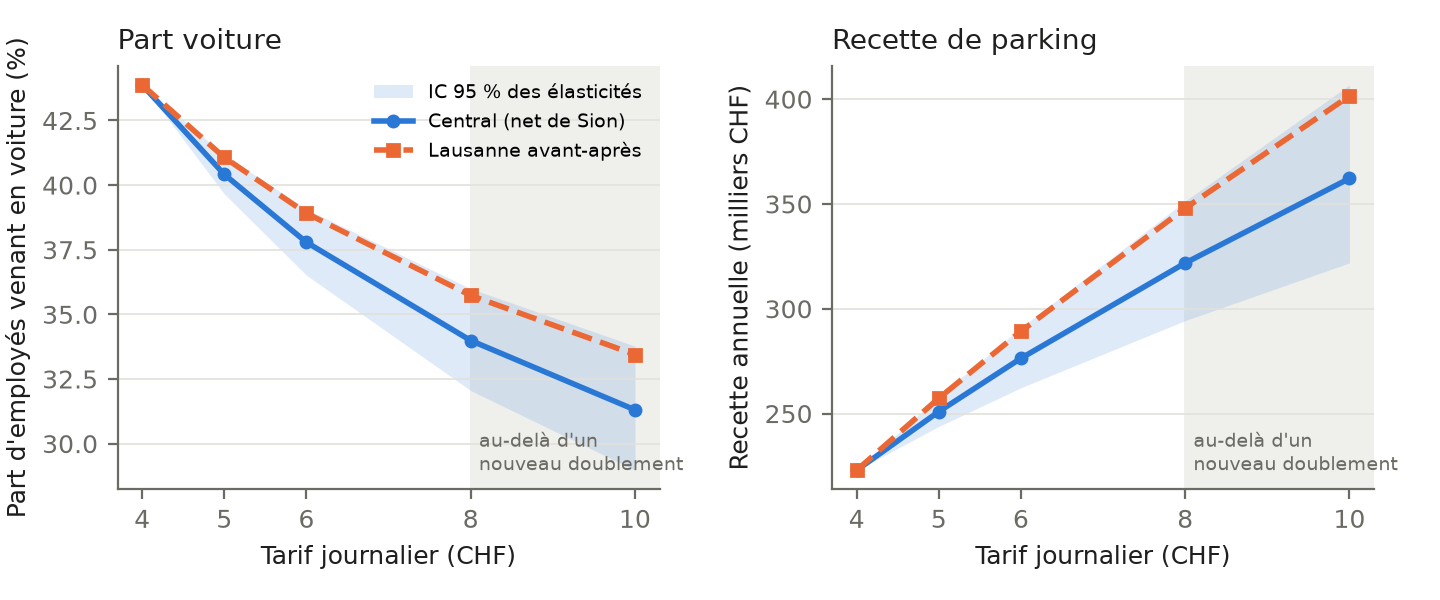

In [15]:
from IPython.display import Image
Image("output/figures/figure_D1.png")

---
## 5. Partie E : qui paie ?

Dépense annuelle = tarif × jours de voiture × 46, divisée par le **revenu brut observé**.
- (a) moyenne sur **tous** les employés du groupe (non-conducteurs = 0) : exposition moyenne ;
- (b) moyenne sur les **automobilistes 2025** : charge de ceux qui paient réellement ;
- (c) projection au tarif recommandé, avec élasticités propres à chaque classe d'accès TP.

On ne calcule **ni bien-être, ni économies, ni coûts des TP** (non observés).

In [16]:
tE1

,Dimension,Groupe,N employés,N automobilistes 2025,"(a) Tous les employés, 2025 (%)",(b) Automobilistes 2025 (%),(b) Dépense moyenne automobilistes 2025 (CHF/an),"(c) Tous, à 6 CHF (%)","(c) Automobilistes restants, à 6 CHF (%)",Part de la recette 2025 (%)
0,Ensemble,Tous,800,351,0.30,0.69,635,0.40,1.00,100.0
1,Accès TP,Bon,558,176,0.19,0.59,574,0.22,0.85,45.3
2,Accès TP,Moyen,157,97,0.47,0.76,670,0.64,1.11,29.1
3,Accès TP,Faible,85,78,0.76,0.83,730,1.10,1.22,25.5
4,Tercile de revenu (EPT),T1 (bas),261,94,0.35,0.97,617,0.46,1.41,26.0
5,Tercile de revenu (EPT),T2 (moyen),260,109,0.30,0.71,641,0.39,1.03,31.3
6,Tercile de revenu (EPT),T3 (haut),279,148,0.27,0.50,643,0.34,0.73,42.6
7,Enfants < 16 ans,0 enfant,421,143,0.19,0.56,538,0.25,0.81,34.5
8,Enfants < 16 ans,1 enfant,155,77,0.35,0.71,640,0.47,1.04,22.1
9,Enfants < 16 ans,2 enfants ou plus,224,131,0.48,0.83,738,0.63,1.20,43.4


Lecture :
- **Réaction faible ≠ charge faible** : les communes à accès TP faible réagissent à peine mais supportent le taux
  d'effort le plus élevé. C'est un manque d'alternative, pas une indifférence au prix.
- **Bénéfice comportemental** surtout dans les zones bien desservies ; **recette** surtout payée par les hauts revenus
  (en volume) mais le **taux d'effort** est le plus élevé pour le tercile bas.
- **Problème d'équité prévisible** d'un tarif uniforme : ménages avec enfants et zones à accès TP faible.

---
## 6. Partie F et ce qu'il reste à faire

### Fait
- [x] Nettoyage des données (communes, revenus, valeur hors bornes) et contrôles de cohérence
- [x] `transit_access.csv` : 39 communes, indicateurs, score, classe, sources, notes de codage
- [x] Tables A1, B1, B2, B3, C1, C2, C3, D1, E1 et Figure D1 (`output/`)
- [x] Analyse de sélection, effets fixes, bootstrap, sensibilités

### À décider en groupe
- [ ] **Tarif 2026 recommandé** (provisoirement 6 CHF : variable `RECO_FEE` dans `analysis.py`)
- [ ] **Mesures complémentaires** : tarif réduit ou exemption pour accès TP faible ? recyclage de la recette
      (abonnements TP, vélo) ? introduction par étapes ?
- [ ] **Alternative écartée** à présenter (ex. 8 CHF uniforme, ou statu quo à 4 CHF)
- [ ] Élasticités centrales : nettes de Sion (choix actuel) ou Lausanne avant-après ?
- [ ] Valider les choix de nettoyage et la destination « gare » pour l'indice TP
- [ ] Format de rédaction (LaTeX, Word...)

### À rédiger
- [ ] **Rapport technique** (8 pages max, sans page de garde) : texte autour de chaque table, section données,
      notes sous les tableaux de régression (variable dépendante, références, erreurs standard groupées, N),
      Table A1 en version compacte, paragraphe de validation, paragraphe Sion, discussion de la sélection,
      hypothèses de la partie D, interprétation de la partie E, **déclaration d'usage de l'IA**
- [ ] **Mémo politique** (3 pages max, 2 tableaux/figures max) : décision, résultats clés, effet distributif,
      alternative écartée, plan de suivi avec 2 ou 3 indicateurs (ex. part voiture, taux d'occupation du parking,
      taux d'effort des automobilistes à accès TP faible), date de revue et seuil déclenchant un ajustement

### Finitions
- [ ] Supprimer `main.py` (vide) ou le faire pointer vers `analysis.py`
- [ ] Chaque membre relit et vérifie les résultats (exigé par les consignes)
- [ ] Commit et rendu le **8 décembre, 23h59**